In [1]:
# Class notes for Tuesday, nov 3, 2026

print('teeest')

teeest


In [5]:
import pandas as pd

df_clothes = pd.DataFrame(data=[["blue", "S", 10, "shirt"],
                                ["pink", "M", 120, "peacoat"],
                                ["red", "M", 2000, "tracksuit"],
                                ["green", "L", 15, "hat"]])

df_clothes.columns = ("color", "size", "price", "type")

df_clothes

,color,size,price,type
0,blue,S,10,shirt
1,pink,M,120,peacoat
2,red,M,2000,tracksuit
3,green,L,15,hat


In [6]:
# sizing is orginal, so it can be easily encoded

size_mapping = {"S": 1, "M": 2, "L": 3}
df_clothes["size_modified"] = df_clothes["size"].map(size_mapping)
df_clothes

,color,size,price,type,size_modified
0,blue,S,10,shirt,1
1,pink,M,120,peacoat,2
2,red,M,2000,tracksuit,2
3,green,L,15,hat,3


In [7]:
# one hot encoding
# this won't work for data that is already numerical

df_clothes = pd.get_dummies(df_clothes, columns=["color"])
df_clothes

,size,price,type,size_modified,color_blue,color_green,color_pink,color_red
0,S,10,shirt,1,True,False,False,False
1,M,120,peacoat,2,False,False,True,False
2,M,2000,tracksuit,2,False,False,False,True
3,L,15,hat,3,False,True,False,False


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sklearn.preprocessing import LabelEncoder

# good for nominal values
# when we want a number for nominal values but 

class_labels = LabelEncoder()
df_clothes["type_modified"] = class_labels.fit_transform(df_clothes["type"])
df_clothes

,size,price,type,size_modified,color_blue,color_green,color_pink,color_red,type_modified
0,S,10,shirt,1,True,False,False,False,2
1,M,120,peacoat,2,False,False,True,False,1
2,M,2000,tracksuit,2,False,False,False,True,3
3,L,15,hat,3,False,True,False,False,0


In [6]:
# data visualization time ahaha
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

titanic_df = pd.read_csv("titanic.csv")
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.columns
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
titanic_df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [ ]:
titanic_df["embarked_new"]=np.where(titanic_df["Embarked"]=="C", "Cherbourg",
                                    np.where(titanic_df["Embarked"]=="Q", "Queenstown",
                                             "Southampton"))

In [8]:
titanic_df["mr_mrs"] = titanic_df['Name'].str.extract(r'\b(Mr|Mrs|Miss)\b')

In [9]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,embarked_new,mr_mrs
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Southampton,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cherbourg,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Southampton,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Southampton,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Southampton,Mr


In [11]:
titanic_df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

# Basic Plots

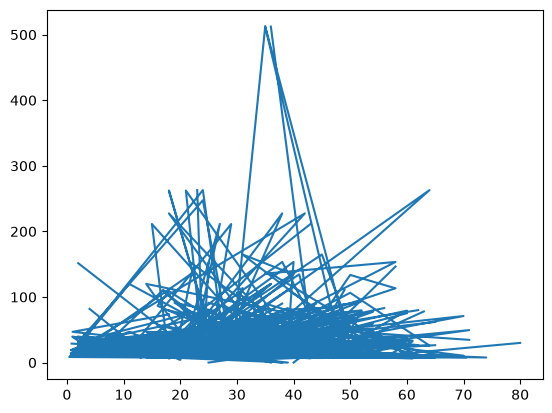

In [12]:
# x-axis, y-axis

plt.plot(titanic_df["Age"], titanic_df["Fare"])

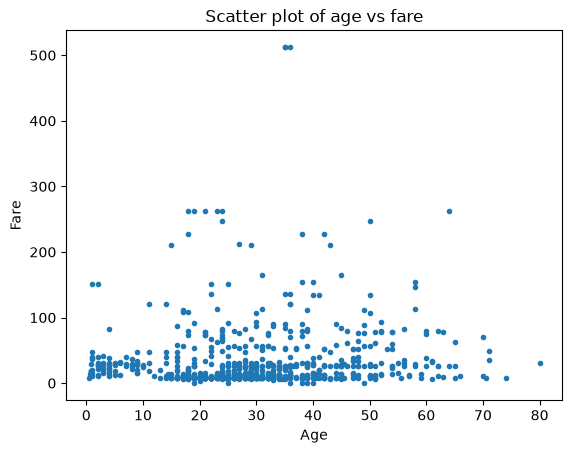

Correlation coef between age and fare: 0.0960666917690389


In [16]:
plt.plot(titanic_df["Age"], titanic_df["Fare"], ".")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Scatter plot of age vs fare")
plt.show()

correlation = titanic_df["Age"].corr(titanic_df["Fare"])
print(f"Correlation coef between age and fare: {correlation}")

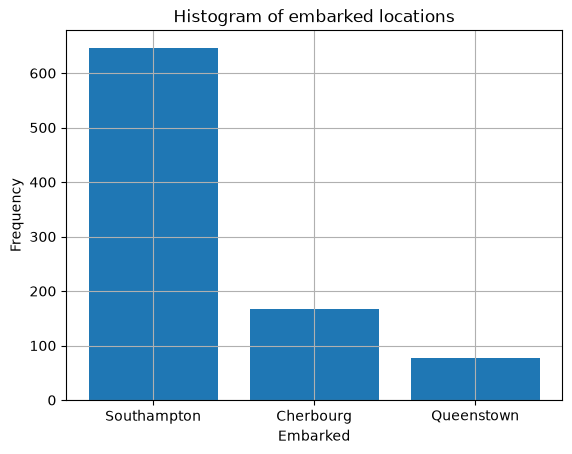

In [20]:
# Histograms show us frequency of whatever column we pass into them
# i.e. how many records have that value

embarked_count = titanic_df["embarked_new"].value_counts()
plt.bar(embarked_count.index, embarked_count.values)
plt.xlabel("Embarked")
plt.ylabel("Frequency")
plt.grid()
plt.title("Histogram of embarked locations")
plt.show()

In [21]:
# Pie charts

agg_gender = titanic_df["Sex"].groupby(titanic_df["Sex"]).count()
agg_gender

Sex
female    314
male      577
Name: Sex, dtype: int64

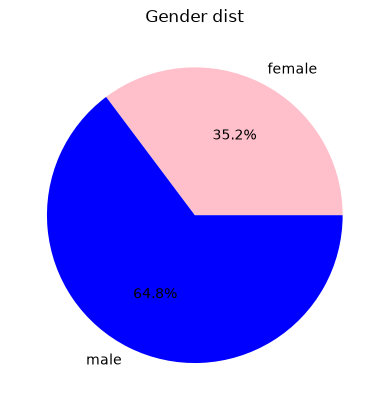

In [23]:
colors = ["pink", "blue"]
agg_gender.plot(kind="pie", colors=colors, autopct="%1.1f%%")
plt.title("Gender dist")
plt.show()

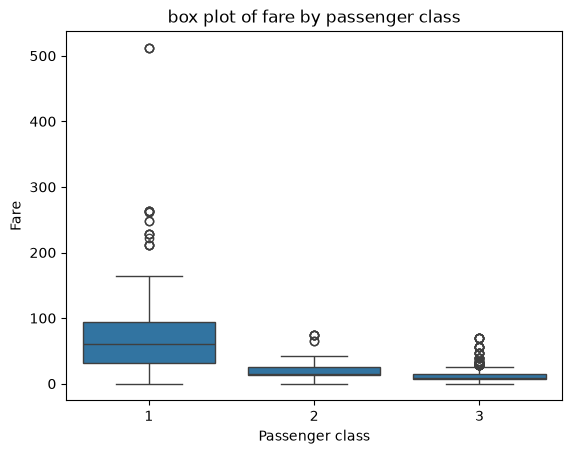

In [26]:
import seaborn as sns

sns.boxplot(data = titanic_df, x="Pclass", y="Fare")
plt.xlabel("Passenger class")
plt.ylabel("Fare")
plt.title("box plot of fare by passenger class")
plt.show()

In [34]:
# One way ANOVA (useful for le final project)
# Null hypothesis: All three classes have the same mean age.
# Alternative hypothesis: At least one class has a different mean age.

from scipy.stats import f_oneway

# remove na values from age
titanic_df = titanic_df.dropna(subset=["Age"])

first_class = titanic_df.loc[titanic_df["Pclass"] == 1, "Age"]
second_class = titanic_df.loc[titanic_df["Pclass"] == 2, "Age"]
third_class = titanic_df.loc[titanic_df["Pclass"] == 3, "Age"]

# High level statistics
print(titanic_df.groupby("Pclass")["Age"].agg(["mean", "std", "count"]))

# ANOVA Test
f_stat, p_value = f_oneway(first_class, second_class, third_class)

df_between = 3-1
df_within = len(titanic_df) - 3

print("df between:", df_between)
print("df within:", df_within)
# If F stat big and p-value small, reject null hypothesis.
# The F stat being big means the group means are likely different.
print("F stat:", f_stat)
print("p-value:", p_value)


             mean        std  count
Pclass                             
1       38.233441  14.802856    186
2       29.877630  14.001077    173
3       25.140620  12.495398    355
df between: 2
df within: 711
F stat: 57.443484340676214
p-value: 7.487984171957457e-24


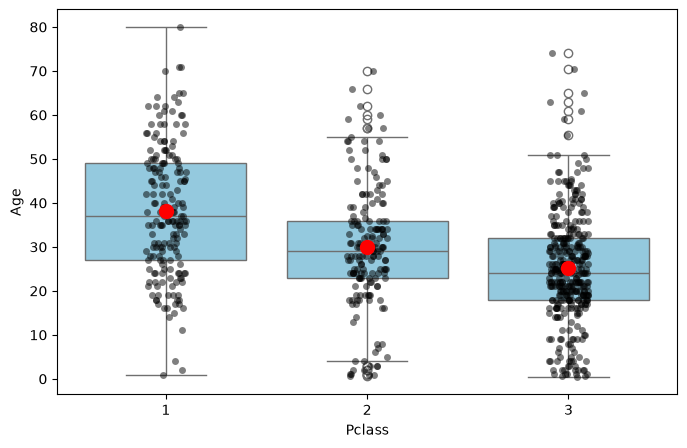

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=titanic_df,
    x="Pclass",
    y="Age",
    color = "skyblue",
    ax=ax
)

sns.stripplot(
    data=titanic_df,
    x="Pclass",
    y="Age",
    color="black",
    alpha=0.5,
    ax=ax
)

means = titanic_df.groupby("Pclass")["Age"].mean()
ax.scatter(x=[0,1,2], y=means.values, color="red", s=100, zorder=3)